# 02 · Shared pipeline: split, CodeCarbon, image cache, regression heads

Every model (mean baseline, ResNet18, MobileNetV3-Large, own CNN) uses what this notebook builds:

1. **Setup**: paths, seed, machine name, GPU check
2. **Split**: the fixed 70/15/15 split from `src/data/split.py`
3. **CodeCarbon**: one helper that wraps every measured run
4. **Image cache**: all 23,053 images decoded once into one `uint8` tensor at 200×200
5. **Regression heads**: ResNet18 and MobileNetV3-Large with a 1-output head

Decisions behind it (user, 2026-11-18): input **200 px** (native, no resizing), split **70/15/15 stratified by age band × race**, seed **655**.

## 1 · Setup

- `REPO`: walk up from the current folder until `requirements.txt` is found, so the notebook works from `src/` or from the repo root.
- `SEED = 655`: the project seed (same as the split and notebook 01).
- `MACHINE`: CodeCarbon numbers depend on the hardware, so every run log records which machine it ran on (`work-pc` / `mac` / `lab`).
- GPU check: a real matrix multiply, not just `torch.cuda.is_available()` (a wrong CUDA build can report `True` and then fail at the first kernel).

In [1]:
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 655
MACHINE = "lab"          # change to "work-pc" or "mac" on the other machines

REPO = Path.cwd()
while not (REPO / "requirements.txt").exists():
    REPO = REPO.parent
SPLIT_CSV = REPO / "splits" / f"utkface_split_seed{SEED}.csv"
IMG_DIR   = REPO / "data" / "raw" / "UTKFace"
CACHE_DIR = REPO / "data" / "cache"            # gitignored, rebuilt on each machine
EMIS_DIR  = REPO / "logs" / "emissions"        # committed: CodeCarbon CSVs
for d in (CACHE_DIR, EMIS_DIR):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"repo     : {REPO}")
print(f"machine  : {MACHINE} | {platform.node()} | {platform.processor() or platform.machine()}")
print(f"torch    : {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    for i in range(torch.cuda.device_count()):
        a = torch.randn(1024, 1024, device=f"cuda:{i}")
        (a @ a).sum().item()                       # forces a real kernel launch
        print(f"  cuda:{i} {torch.cuda.get_device_name(i)}  matmul OK")

repo     : /home/gtu-dsa/robotics/fouad_other/CSE655_Deep_Learning_Project
machine  : lab | gtu-dsa | x86_64
torch    : 2.15.0+cu132 | device: cuda
  cuda:0 NVIDIA GeForce RTX 5090  matmul OK


  cuda:1 NVIDIA GeForce RTX 5090  matmul OK


## 2 · The split

`splits/utkface_split_seed655.csv` is made once by `python src/data/split.py` and committed, so every machine and every model uses exactly the same images.

- One row per clean image: `file`, `age` (the regression target), `gender`, `race`, `age_band`, `split`.
- Per age band × race stratum: shuffle with the seed, `round(0.15·n)` → test, `round(0.15·n)` → val, rest → train.
- **Rule:** train is for fitting, val for every choice we make (epochs, learning rate, …), **test only once per final model**.

The checks below make sure the CSV matches the images on disk and that no image is in two splits.

In [2]:
split_df = pd.read_csv(SPLIT_CSV)
GENDER = {0: "male", 1: "female"}
RACE   = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}

# sanity checks
assert split_df.file.is_unique, "an image appears twice"
missing = [f for f in split_df.file if not (IMG_DIR / f).exists()]
assert not missing, f"{len(missing)} files missing in {IMG_DIR}"

display(split_df.head())

counts = split_df.split.value_counts().reindex(["train", "val", "test"])
print(pd.DataFrame({"images": counts, "share %": (100 * counts / len(split_df)).round(2)}))
print(f"\ntotal: {len(split_df)} images, all present on disk")
print("\nage (target) per split:")
print(split_df.groupby("split").age.describe()[["mean", "50%", "std", "min", "max"]].reindex(["train", "val", "test"]).round(2))

,file,age,gender,race,age_band,split
0,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0,80+,test
1,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0,80+,train
2,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0,80+,test
3,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0,80+,train
4,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0,80+,train


       images  share %
split                 
train   16131    69.97
val      3461    15.01
test     3461    15.01

total: 23053 images, all present on disk

age (target) per split:
        mean   50%    std  min    max
split                                
train  33.23  29.0  19.89  1.0  116.0
val    33.26  29.0  19.88  1.0  116.0
test   33.33  29.0  20.01  1.0  116.0


## 3 · CodeCarbon: one helper for every measured run

The assignment requires **every** training and evaluation run to be measured, including tests, hyperparameter searches and **failed** runs. So we never call CodeCarbon by hand; everything goes through `track(...)`:

```python
with track("resnet18_ft_run01", kind="train", gpu_ids=[0]) as info:
    train(...)
    info["val_mae"] = 5.1        # anything put in `info` is saved in the run log
```

What happens:
1. `OfflineEmissionsTracker` starts; every `measure_power_secs = 5` s it samples power: **GPU** from the NVIDIA driver (NVML, a real measurement), **CPU** and **RAM** estimated **for our process only** (`tracking_mode="process"`, `force_mode_cpu_load=True`): CPU power = TDP × (our CPU time ÷ wall time ÷ number of cores).
   *Why not RAPL?* RAPL measures the whole CPU package. The lab machine is shared (other users' LLM server and simulators draw ~120 W of CPU), so RAPL would charge their load to our runs.
2. Energy (kWh) = Σ power × time. Emissions (kg CO2eq) = energy × carbon intensity of the **Turkish grid** (`country_iso_code="TUR"`, offline mode, so no internet lookup).
3. When the block ends, normally **or with an error**, the tracker stops and writes one row to `logs/emissions/emissions.csv` (CodeCarbon's own file) and one row to `logs/runs.csv` (our summary with machine, status and `info`).

`gpu_ids=[0]` measures only the GPU the run uses; GPU 1 is used by another user's Ollama server. NVML measures the **whole** GPU, so `track` warns (and logs `other_gpu_procs`) if anything else runs on our GPU.

The last lines run a **10-second matmul test** to check that the tracker works. That test is itself logged (`kind="test"`), as required.

In [3]:
import logging
from contextlib import contextmanager
from datetime import datetime

from codecarbon import OfflineEmissionsTracker

RUNS_CSV = REPO / "logs" / "runs.csv"
logging.getLogger("codecarbon").setLevel(logging.ERROR)

def other_gpu_processes(gpu_ids) -> list[str]:
    """Processes of OTHER users/programs on the GPUs we measure (NVML measures the whole GPU)."""
    import os, subprocess
    uuids = subprocess.run(["nvidia-smi", "--query-gpu=index,uuid", "--format=csv,noheader"],
                           capture_output=True, text=True).stdout.strip().splitlines()
    ours = {u.split(", ")[1] for u in uuids if gpu_ids is None or int(u.split(", ")[0]) in gpu_ids}
    apps = subprocess.run(["nvidia-smi", "--query-compute-apps=gpu_uuid,pid,process_name", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().splitlines()
    return [a.split(", ")[2] for a in apps if a and a.split(", ")[0] in ours and int(a.split(", ")[1]) != os.getpid()]

def already_logged(run_name: str) -> bool:
    """True if a run with this name is already in logs/runs.csv (used so demo cells run only once)."""
    return RUNS_CSV.exists() and (pd.read_csv(RUNS_CSV).run == run_name).any()

@contextmanager
def track(run_name: str, kind: str, gpu_ids=None, notes: str = ""):
    """Measure the energy/CO2 of the code inside the `with` block and log it, even if it fails.
    kind: 'test' | 'prep' | 'train' | 'eval' | 'search'"""
    tracker = OfflineEmissionsTracker(
        project_name=f"cse655_{run_name}", country_iso_code="TUR",
        output_dir=str(EMIS_DIR), output_file="emissions.csv",
        gpu_ids=gpu_ids, measure_power_secs=5, log_level="error", allow_multiple_runs=True,
        tracking_mode="process", force_mode_cpu_load=True)   # count only OUR process's CPU time (shared machine)
    others = other_gpu_processes(gpu_ids)
    if others:
        print(f"WARNING: other processes on GPU {gpu_ids}: {others} -> their power is counted too")
    info, status = {}, "ok"
    tracker.start()
    try:
        yield info
    except BaseException:
        status = "failed"
        raise
    finally:
        kg = tracker.stop() or 0.0
        d = tracker.final_emissions_data
        row = {"timestamp": datetime.now().isoformat(timespec="seconds"), "run": run_name, "kind": kind,
               "machine": MACHINE, "status": status, "duration_s": round(d.duration, 1),
               "energy_kwh": d.energy_consumed, "cpu_kwh": d.cpu_energy, "gpu_kwh": d.gpu_energy,
               "ram_kwh": d.ram_energy, "kg_co2": kg, "gpu_ids": str(gpu_ids), "other_gpu_procs": len(others),
               "cpu_mode": "process-estimate", "notes": notes, **info}
        # read + concat + rewrite (not append): new columns from `info` must not shift old rows
        log = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
        pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RUNS_CSV, index=False)
        print(f"[{run_name}] {status} | {d.duration:.1f} s | {1000 * d.energy_consumed:.3f} Wh "
              f"(cpu {1000 * d.cpu_energy:.3f}, gpu {1000 * d.gpu_energy:.3f}, ram {1000 * d.ram_energy:.3f}) "
              f"| {1000 * kg:.3f} g CO2eq")

# --- check that the tracker works: ~10 s of matmuls on cuda:0 (runs only once; set RUN_SMOKE_TEST = True to repeat) ---
RUN_SMOKE_TEST = not (RUNS_CSV.exists() and (pd.read_csv(RUNS_CSV).notes.str.contains("process mode")).any())
if RUN_SMOKE_TEST:
    with track("test_codecarbon", kind="test", gpu_ids=[0], notes="tracker smoke test v2 (process mode), 10 s matmul") as info:
        a = torch.randn(4096, 4096, device="cuda:0")
        t0, n = time.time(), 0
        while time.time() - t0 < 10:
            a = (a @ a).tanh(); n += 1
        torch.cuda.synchronize()
        info["matmuls"] = n

last = pd.read_csv(EMIS_DIR / "emissions.csv").iloc[-1]
print(f"carbon intensity used: {1000 * last.emissions / last.energy_consumed:.0f} g CO2eq/kWh")
with pd.option_context("display.width", 200, "display.max_columns", 30):
    display(pd.read_csv(RUNS_CSV)[["run", "kind", "machine", "status", "duration_s", "energy_kwh", "cpu_kwh", "gpu_kwh", "ram_kwh", "kg_co2", "cpu_mode", "notes"]])

carbon intensity used: 465 g CO2eq/kWh


,run,kind,machine,status,duration_s,energy_kwh,cpu_kwh,gpu_kwh,ram_kwh,kg_co2,cpu_mode,notes
0,test_codecarbon,test,lab,ok,10.7,1.728472e-03,5.617972e-05,0.001559,1.130860e-04,8.030238e-04,machine-estimate,"tracker smoke test, 10 s matmul"
1,test_codecarbon,test,lab,ok,10.8,1.618190e-03,1.597675e-05,0.001573,2.969647e-05,7.517886e-04,process-estimate,"tracker smoke test v2 (process mode), 10 s matmul"
2,prep_cache_200,prep,lab,ok,6.2,1.462752e-04,2.616450e-05,0.000103,1.664313e-05,6.795741e-05,process-estimate,"decode all JPEGs once into uint8 (N,3,200,200)"
3,test_heads_forward,test,lab,ok,6.4,1.276798e-04,9.561103e-07,0.000109,1.765413e-05,5.931823e-05,process-estimate,"forward 4 images through both models, shape check"
4,test_heads_forward,test,lab,ok,0.2,6.276838e-06,5.952221e-07,0.000005,6.018894e-07,2.916131e-06,process-estimate,"forward 4 images through both models, shape check"
5,eval_baseline_mean_median,eval,lab,ok,0.0,1.629371e-06,0.000000e+00,0.000002,2.325886e-08,7.569831e-07,process-estimate,constant predictors from train stats
6,eval_baseline_mean_median,eval,lab,ok,0.0,3.908734e-08,1.623471e-08,0.000000,2.285263e-08,1.815943e-08,process-estimate,constant predictors from train stats
7,test_heads_forward,test,lab,ok,0.3,4.957862e-06,6.457325e-07,0.000004,6.399041e-07,2.303353e-06,process-estimate,"forward 4 images through both models, shape check"
8,test_augment_demo,test,lab,ok,0.0,4.348738e-08,1.738833e-08,0.000000,2.609906e-08,2.020363e-08,process-estimate,"copy train/val to GPU, show 8 augmented images"
9,test_heads_forward,test,lab,ok,0.3,6.117845e-06,6.372282e-07,0.000005,6.458903e-07,2.842265e-06,process-estimate,"forward 4 images through both models, shape check"


## 4 · Image cache: decode every JPEG once

Training reads every image once per epoch. Decoding 23,053 JPEGs again in every epoch of every run wastes CPU time and energy, so we decode them **once** and store the raw pixels (the assignment lists "caching pre-processed data" as a footprint-reduction technique).

**Format:** one NumPy array `images` of shape **(N, 3, 200, 200)**, dtype **`uint8`** (0–255), rows in the same order as `split_df`.
- Size: 23,053 × 3 × 200 × 200 = 2,766,360,000 values × 1 byte = **2.77 GB**.
  As `float32` it would be 4 × larger (11.1 GB), so we keep `uint8` and convert to float on the GPU, one batch at a time.
- Channels first `(C, H, W)` because that is what PyTorch's `Conv2d` expects; PIL/NumPy give `(H, W, C)`, so each image is transposed once here.
- No resizing (decision: 200 px native). The ImageNet normalisation is **not** applied here; it happens per batch, so the same cache also serves the own CNN.

**Saved as** `data/cache/utkface_200_uint8.npy` (gitignored; each machine builds its own). Loading with `mmap_mode="r"` maps the file without reading all 2.77 GB at once.

This is a measured run (`kind="prep"`). It is skipped if the cache already exists, so re-running the notebook does not spend energy again. The checks at the end compare a few cached images with a fresh decode of the JPEG and show them with their labels, so we can see that rows and labels still match.

cache exists, not rebuilt: utkface_200_uint8.npy
images: shape (23053, 3, 200, 200), dtype uint8, 2.77 GB on disk
8 random rows are identical to a fresh decode of their JPEG


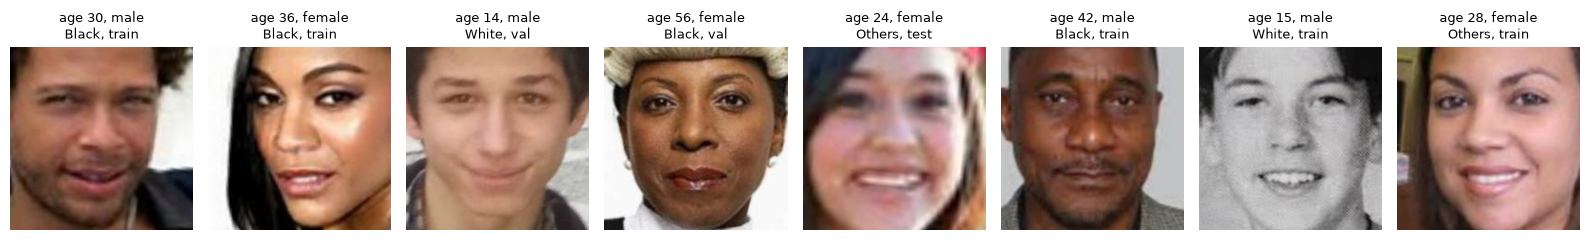

In [4]:
from concurrent.futures import ThreadPoolExecutor

from PIL import Image
import matplotlib.pyplot as plt

IMG_SIZE = 200
CACHE_NPY = CACHE_DIR / f"utkface_{IMG_SIZE}_uint8.npy"
CACHE_FILES = CACHE_DIR / f"utkface_{IMG_SIZE}_files.csv"   # row order of the cache

def load_chw(file: str) -> np.ndarray:
    """JPEG -> uint8 array (3, 200, 200)."""
    with Image.open(IMG_DIR / file) as im:
        a = np.asarray(im.convert("RGB"))                          # (H, W, C)
    assert a.shape == (IMG_SIZE, IMG_SIZE, 3), f"{file}: {a.shape}"
    return a.transpose(2, 0, 1)                                    # (C, H, W)

if not CACHE_NPY.exists():
    with track("prep_cache_200", kind="prep", gpu_ids=[0], notes="decode all JPEGs once into uint8 (N,3,200,200)") as info:
        t0 = time.time()
        out = np.lib.format.open_memmap(CACHE_NPY, mode="w+", dtype=np.uint8,
                                        shape=(len(split_df), 3, IMG_SIZE, IMG_SIZE))
        with ThreadPoolExecutor(max_workers=16) as pool:           # PIL releases the GIL while decoding
            for i, arr in enumerate(pool.map(load_chw, split_df.file, chunksize=64)):
                out[i] = arr
        out.flush(); del out
        split_df[["file"]].to_csv(CACHE_FILES, index=False)
        info["n_images"] = len(split_df); info["seconds"] = round(time.time() - t0, 1)
else:
    print(f"cache exists, not rebuilt: {CACHE_NPY.name}")

# --- load (memory-mapped) and check ---
images = np.load(CACHE_NPY, mmap_mode="r")
assert (pd.read_csv(CACHE_FILES).file.values == split_df.file.values).all(), "cache rows != split rows"
print(f"images: shape {images.shape}, dtype {images.dtype}, {images.nbytes / 1e9:.2f} GB on disk")

check = np.random.default_rng(SEED).choice(len(split_df), 8, replace=False)
for i in check:
    assert np.array_equal(images[i], load_chw(split_df.file[i])), f"row {i} differs from its JPEG"
print("8 random rows are identical to a fresh decode of their JPEG")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, check):
    r = split_df.iloc[i]
    ax.imshow(images[i].transpose(1, 2, 0))                       # back to (H, W, C) for plotting
    ax.set_title(f"age {r.age}, {GENDER[r.gender]}\n{RACE[r.race]}, {r.split}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5 · Standard models with a regression head

Both models are loaded with **ImageNet weights** (transfer learning) and only their **last layer** is replaced: ImageNet has 1000 classes, we predict **one number** (age).

| model | weights (decided) | ImageNet top-1 | original last layer | new last layer |
|---|---|---|---|---|
| ResNet18 | `IMAGENET1K_V1` | 69.76 % | `fc = Linear(512, 1000)` | `fc = Linear(512, 1)` |
| MobileNetV3-Large | `IMAGENET1K_V1` | 74.04 % | `classifier[3] = Linear(1280, 1000)` | `classifier[3] = Linear(1280, 1)` |

**Parameter counts by hand** (Linear: `in × out + out` for the bias):
- ResNet18: 11,689,512 − (512·1000 + 1000) + (512·1 + 1) = 11,689,512 − 513,000 + 513 = **11,177,025**
- MobileNetV3-L: 5,483,032 − (1280·1000 + 1000) + (1280·1 + 1) = 5,483,032 − 1,281,000 + 1,281 = **4,203,313**

The new layer starts with random weights; everything before it keeps the ImageNet weights.

**Input preprocessing (`to_input`)**, done on the GPU per batch from the `uint8` cache:
`x = (pixel / 255 − mean) / std` with the ImageNet `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`, the scale the pretrained weights were trained on. No resize/crop (200 px).

The test at the end pushes 4 cached images through each model on `cuda:0` and checks that the output has shape `(4, 1)`, one predicted age per image. The predictions are meaningless for now (the head is untrained). This forward pass is logged as a `test` run.

In [5]:
import torch.nn as nn
import torchvision
from torchinfo import summary

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_input(batch_uint8: np.ndarray, device: str) -> torch.Tensor:
    """uint8 (B, 3, 200, 200) from the cache -> normalised float32 on the device."""
    # np.array(...) copies the batch out of the read-only memory-mapped cache (torch needs a writable array)
    x = torch.from_numpy(np.array(batch_uint8)).to(device).float().div_(255)
    return (x - IMAGENET_MEAN.to(device)) / IMAGENET_STD.to(device)

def build_model(name: str, pretrained: bool = True) -> nn.Module:
    if name == "resnet18":
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.fc)
        m.fc = nn.Linear(m.fc.in_features, 1)                         # 512 -> 1
        print("  new head     :", m.fc)
    elif name == "mobilenet_v3_large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.classifier[3])
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)   # 1280 -> 1
        print("  new head     :", m.classifier[3])
    else:
        raise ValueError(name)
    return m

def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_heads_forward"):
    x = to_input(images[:4], "cuda:0")
    print(f"input batch: {tuple(x.shape)} {x.dtype}, mean {x.mean():.3f}, std {x.std():.3f}\n")

    with track("test_heads_forward", kind="test", gpu_ids=[0], notes="forward 4 images through both models, shape check") as info:
        for name in ("resnet18", "mobilenet_v3_large"):
            print(name)
            model = build_model(name).to("cuda:0").eval()
            with torch.no_grad():
                y = model(x)
            assert y.shape == (4, 1)
            print(f"  params: {n_params(model):,} | output shape {tuple(y.shape)} | untrained predictions {y.squeeze(1).tolist()}\n")
            info[f"params_{name}"] = n_params(model)

    print(summary(build_model("resnet18", pretrained=False), input_size=(1, 3, 200, 200), depth=1,
                  col_names=("output_size", "num_params", "mult_adds"), verbose=0))
else:
    print("demo 'test_heads_forward' already ran and is logged - skipped")

input batch: (4, 3, 200, 200) torch.float32, mean 0.440, std 0.989



resnet18
  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
  params: 11,177,025 | output shape (4, 1) | untrained predictions [-0.06837485730648041, -0.5078461766242981, -0.6266655921936035, -0.15977643430233002]

mobilenet_v3_large
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


  params: 4,203,313 | output shape (4, 1) | untrained predictions [0.012532620690762997, -0.019658535718917847, -0.01390224788337946, -0.03776223957538605]

[test_heads_forward] ok | 0.2 s | 0.006 Wh (cpu 0.001, gpu 0.005, ram 0.001) | 0.003 g CO2eq
  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
ResNet                                   [1, 1]                    --                        --
├─Conv2d: 1-1                            [1, 64, 100, 100]         9,408                     94,080,000
├─BatchNorm2d: 1-2                       [1, 64, 100, 100]         128                       128
├─ReLU: 1-3                              [1, 64, 100, 100]         --                        --
├─MaxPool2d: 1-4                         [1, 64, 50, 50]           --                        --
├─Sequential: 1-5  

## 6 · Shared evaluation + the mean / median baseline

**One `evaluate()` for every model**, so all numbers in the results table are computed the same way (assignment 3.3: "same evaluation code for all models"). With $y_i$ = true age, $\hat y_i$ = prediction, $n$ images:

| metric | formula | meaning |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | average error in **years**; the main metric |
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | also years, but large errors count more (squared) |
| R² | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | share of the age variance explained; **0 = no better than predicting the mean**, 1 = perfect |

Plus **MAE per group** (gender, race, age band), required because UTKFace contains faces with group labels.

**Baseline (assignment 3.1):** ignore the image and always predict one number computed on **train** only:
- mean of train ages → minimises the squared error (best constant for RMSE)
- median of train ages → minimises the absolute error (best constant for MAE)

The baseline is a final "model" with nothing to tune, so it is evaluated on **val and test now**. Its test MAE is $\text{MAE}_\text{mean}$ in the acceptability rule, so it also gives us the first target:
$\text{MAE}_\text{own} \le 0.6 \times \text{MAE}_\text{mean}$.

Results go to `results/results.csv` (one row per model, the columns of the table in assignment 3.5) and the per-group errors to `results/per_group/`. The run is measured (`kind="eval"`).

In [4]:
RESULTS_CSV = REPO / "results" / "results.csv"
GROUP_DIR = REPO / "results" / "per_group"
GROUP_DIR.mkdir(parents=True, exist_ok=True)
AGE_BANDS = ["0-2", "3-12", "13-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

def evaluate(y_true, y_pred, meta: pd.DataFrame | None = None) -> tuple[dict, pd.DataFrame | None]:
    """Shared metrics for every model. meta: rows of split_df in the same order (for per-group MAE)."""
    y, p = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    err = p - y
    metrics = {"mae": np.abs(err).mean(),
               "rmse": np.sqrt((err ** 2).mean()),
               "r2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
               "n": len(y)}
    groups = None
    if meta is not None:
        m = meta.assign(abs_err=np.abs(err), gender=meta.gender.map(GENDER), race=meta.race.map(RACE))
        groups = pd.concat([m.groupby(col).abs_err.agg(mae="mean", n="size").assign(group=col)
                            for col in ("gender", "race", "age_band")])
        groups = groups.rename_axis("value").reset_index()[["group", "value", "n", "mae"]]
        order = list(GENDER.values()) + list(RACE.values()) + AGE_BANDS          # natural order, not alphabetical
        groups = groups.sort_values("value", key=lambda s: s.map(order.index), kind="stable")
    return metrics, groups

def save_result(row: dict) -> None:
    """One row per model in results/results.csv (re-running a model replaces its row)."""
    log = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()
    if len(log):
        log = log[log.model != row["model"]]
    pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)

train = split_df[split_df.split == "train"]
val   = split_df[split_df.split == "val"].reset_index(drop=True)
test  = split_df[split_df.split == "test"].reset_index(drop=True)

with track("eval_baseline_mean_median", kind="eval", gpu_ids=[0], notes="constant predictors from train stats") as info:
    rows = []
    for name, const in (("mean", train.age.mean()), ("median", train.age.median())):
        for split_name, part in (("val", val), ("test", test)):
            m, g = evaluate(part.age, np.full(len(part), const), part)
            rows.append({"baseline": name, "constant": round(const, 3), "split": split_name,
                         **{k: round(v, 3) for k, v in m.items() if k != "n"}, "n": m["n"]})
            if split_name == "test":
                g.to_csv(GROUP_DIR / f"baseline_{name}_test.csv", index=False)
                info[f"{name}_test_mae"] = round(m["mae"], 4)
    table = pd.DataFrame(rows)

print(table.to_string(index=False))

mae_mean = table.query("baseline == 'mean' and split == 'test'").mae.item()
print(f"\nMAE_mean (test)          = {mae_mean:.3f} years")
print(f"target 0.6 × MAE_mean    = {0.6 * mae_mean:.3f} years  <- own CNN must be at or below this (and ≤ 1.15 × MAE_best)")

for name in ("mean", "median"):
    r = table.query("baseline == @name and split == 'test'").iloc[0]
    save_result({"model": f"{name} baseline", "machine": MACHINE, "params": 0, "mflops_per_img": 0,
                 "test_mae": r.mae, "test_rmse": r.rmse, "test_r2": r.r2,
                 "train_kwh": 0, "train_kg_co2": 0, "project_kg_co2": None, "ms_per_img": 0})

print("\nper-group test MAE of the mean baseline:")
g = pd.read_csv(GROUP_DIR / "baseline_mean_test.csv")
with pd.option_context("display.width", 200):
    for col in ("gender", "race", "age_band"):
        t = g[g.group == col].set_index("value")[["n", "mae"]].T
        print(t.apply(lambda r: r.map("{:.0f}".format if r.name == "n" else "{:.2f}".format), axis=1).to_string(), "\n")

[eval_baseline_mean_median] ok | 0.0 s | 0.000 Wh (cpu 0.000, gpu 0.000, ram 0.000) | 0.000 g CO2eq
baseline  constant split    mae   rmse     r2    n
    mean    33.228   val 15.323 19.876 -0.000 3461
    mean    33.228  test 15.400 20.007 -0.000 3461
  median    29.000   val 14.935 20.327 -0.046 3461
  median    29.000  test 15.072 20.471 -0.047 3461

MAE_mean (test)          = 15.400 years
target 0.6 × MAE_mean    = 9.240 years  <- own CNN must be at or below this (and ≤ 1.15 × MAE_best)

per-group test MAE of the mean baseline:
value   male female
n       1802   1659
mae    15.82  14.95 

value  White  Black  Asian Indian Others
n       1474    662    505    578    242
mae    17.89  10.60  16.97  13.60  14.35 

value    0-2   3-12  13-19 20-29 30-39  40-49  50-59  60-69  70-79    80+
n        238    266    172  1064   666    328    335    192    101     99
mae    31.90  26.28  17.23  7.89  2.51  10.54  20.73  30.08  40.86  54.36 



## 7 · Training data on the GPU + augmentation

**Decisions (user, 2026-11-18):** fine-tuning option **A** (head first, then only the last layers; early layers stay frozen), **L1 loss**, augmentation **flip + shift + greyscale**, max 15 epochs with early stopping (patience 3), bf16 mixed precision.

**Data on the GPU.** Train + val as `uint8` = (16,131 + 3,461) × 120,000 B = **2.35 GB**, which fits easily in the 32 GB of the RTX 5090. We copy it **once**; afterwards every batch is just an index into GPU memory: no DataLoader workers, no JPEG decoding, no CPU→GPU copy per batch. That keeps the CPU (and its energy) almost idle during training.

**Batch pipeline** `make_batch(X, idx, train)`:
1. `uint8 → float / 255` → values in [0, 1]
2. **train only**, each image independently:
   - **horizontal flip**, p = 0.5: a face mirrored left↔right is still the same age
   - **rotation** by a random angle `a ∈ [−10°, +10°]` and **shift** by `dx, dy ∈ [−8, 8]` pixels, both in **one** affine transform (so the image is interpolated only once, bilinear). Teaches the model that small head tilts and the exact face position do not matter (UTKFace faces are aligned, but not perfectly).
     Empty corners/borders are filled with **black (zeros)**, not with a mirror image: reflection would create fake face content (a second ear, mirrored hair) that the model could treat as a real feature; black carries no face information (decision: user).
   - **greyscale**, p = 0.1: `Y = 0.299 R + 0.587 G + 0.114 B` (ITU-R 601 luma, same as PIL / torchvision), copied to all 3 channels. The EDA found 868 b&w photos (3.66 %), rare among children and some groups, so the model could learn "b&w → old"; showing colour photos in b&w breaks that shortcut
3. ImageNet normalisation `(x − mean) / std`

Val and test images are **never** augmented. The figure shows the same 8 training faces: original (top), one random augmentation (middle), and, only to show that it works, the same augmentation with greyscale forced to p = 1 (bottom; training uses p = 0.1).

on cuda:0: X_train (16131, 3, 200, 200) torch.uint8, X_val (3461, 3, 200, 200)  -> 2.35 GB
y_train: mean 33.228 (= mean baseline constant), min 1, max 116


[test_augment_demo] ok | 0.1 s | 0.002 Wh (cpu 0.000, gpu 0.002, ram 0.000) | 0.001 g CO2eq


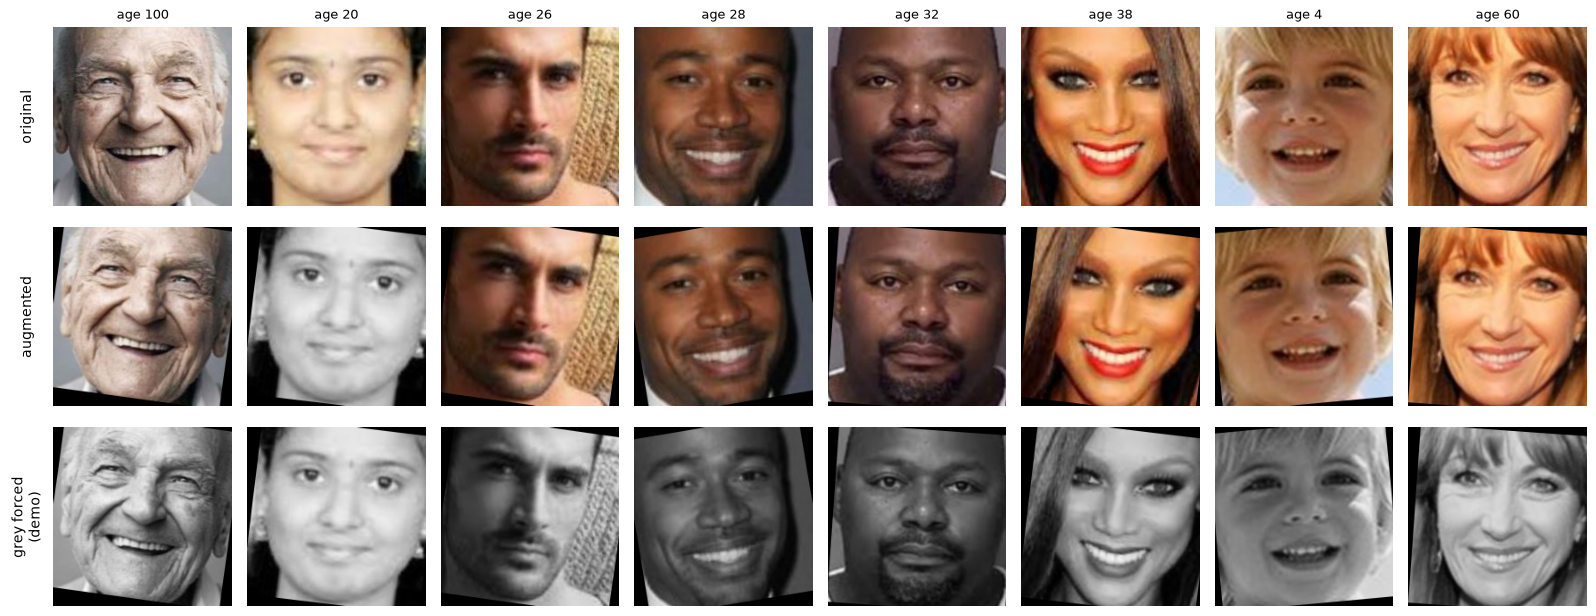

In [6]:
import torch.nn.functional as F

DEV = "cuda:0"                                  # GPU 1 is used by another user (Ollama)
tr_idx = np.flatnonzero(split_df.split.values == "train")
va_idx = np.flatnonzero(split_df.split.values == "val")

X_train = torch.from_numpy(np.array(images[tr_idx])).to(DEV)          # uint8 (16131, 3, 200, 200)
X_val   = torch.from_numpy(np.array(images[va_idx])).to(DEV)          # uint8 ( 3461, 3, 200, 200)
y_train = torch.tensor(split_df.age.values[tr_idx], dtype=torch.float32, device=DEV)
y_val   = torch.tensor(split_df.age.values[va_idx], dtype=torch.float32, device=DEV)
MEAN_D, STD_D = IMAGENET_MEAN.to(DEV), IMAGENET_STD.to(DEV)
LUMA = torch.tensor([0.299, 0.587, 0.114], device=DEV).view(1, 3, 1, 1)

def augment(x: torch.Tensor, max_shift: int = 8, max_deg: float = 10.0, p_grey: float = 0.1,
            gen: torch.Generator | None = None) -> torch.Tensor:
    """x: float (B, 3, H, W) in [0, 1]. Per image: random flip, rotation + shift, greyscale."""
    B, _, H, W = x.shape
    r = lambda *s: torch.rand(*s, device=x.device, generator=gen)
    flip = r(B) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    # rotation + shift in ONE affine matrix  theta = [[cos a, -sin a, tx], [sin a, cos a, ty]]
    # grid_sample uses coordinates in [-1, 1], so 1 pixel = 2/W  ->  tx = 2*dx/W
    a = (r(B) * 2 - 1) * max_deg * torch.pi / 180                       # radians in [-10°, +10°]
    d = torch.floor(r(B, 2) * (2 * max_shift + 1)) - max_shift          # integers in [-8, 8]
    theta = torch.stack([torch.stack([a.cos(), -a.sin(), 2 * d[:, 0] / W], 1),
                         torch.stack([a.sin(),  a.cos(), 2 * d[:, 1] / H], 1)], 1)   # (B, 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    grey = r(B) < p_grey
    y = (x * LUMA).sum(1, keepdim=True).expand(-1, 3, -1, -1)
    return torch.where(grey.view(B, 1, 1, 1), y, x)

def make_batch(X: torch.Tensor, idx: torch.Tensor, train: bool) -> torch.Tensor:
    x = X[idx].float().div_(255)
    if train:
        x = augment(x)
    return (x - MEAN_D) / STD_D

print(f"on {DEV}: X_train {tuple(X_train.shape)} {X_train.dtype}, X_val {tuple(X_val.shape)}  "
      f"-> {(X_train.nbytes + X_val.nbytes) / 1e9:.2f} GB")
print(f"y_train: mean {y_train.mean():.3f} (= mean baseline constant), min {y_train.min():.0f}, max {y_train.max():.0f}")

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_augment_demo"):
    # --- show 8 training images: original / augmented / augmented with greyscale forced (demo only) ---
    with track("test_augment_demo", kind="test", gpu_ids=[0], notes="copy train/val to GPU, show augmented images (rotation + zeros)"):
        idx = torch.arange(8, device=DEV) * 2000
        x01 = X_train[idx].float() / 255
        rows = [x01,
                augment(x01, gen=torch.Generator(DEV).manual_seed(SEED)),
                augment(x01, p_grey=1.0, gen=torch.Generator(DEV).manual_seed(SEED))]   # same flips/angles/shifts
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
    for i, (row, label) in enumerate(zip(rows, ["original", "augmented", "grey forced\n(demo)"])):
        for j in range(8):
            axes[i, j].imshow(row[j].permute(1, 2, 0).cpu()); axes[i, j].axis("off")
        axes[i, 0].text(-30, 100, label, rotation=90, va="center", ha="center")
    for j in range(8):
        axes[0, j].set_title(f"age {y_train[idx[j]]:.0f}", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("demo 'test_augment_demo' already ran and is logged - skipped")

## 8 · Freezing plan (option A): what trains in each phase

**Rule:** unfreeze only the layers that work on the **small, deep feature maps (13×13 and 7×7)**. They hold ImageNet-specific features (objects) that must adapt to age. The early layers (100×100 → 25×25) hold generic edges and textures and stay frozen with their ImageNet weights.

| phase | ResNet18 trains | MobileNetV3-L trains | epochs |
|---|---|---|---|
| **1 · head** | `fc` (new, 513 params) | `classifier[3]` (new, 1,281 params) | 1 |
| **2 · last layers** | `layer3`, `layer4`, `fc` | `features[7:]` (blocks at 13×13 and 7×7), `classifier` | ≤ 14, early stopping |

`set_phase()` does two things:
1. `requires_grad = False` for every frozen parameter, so the optimizer cannot change it and no weight gradient is computed.
2. **BatchNorm in frozen layers stays in `eval()` mode.** In `train()` mode BN would keep updating its running mean/variance with our faces even though its weights are frozen, which silently changes the "frozen" layers.

**Why this saves energy.** One training step = forward pass (F) + backward pass. Backward through a layer costs about 2× its forward (gradient w.r.t. the input and w.r.t. the weights). A frozen layer **before** all trainable layers needs **no backward at all**. So, as an estimate,

$$\text{step cost} \approx F_\text{all} + 2\,F_\text{trainable} \qquad \text{vs. full fine-tuning} \approx 3\,F_\text{all}$$

MACs are counted with a hook on every `Conv2d` and `Linear`: conv MACs = output elements × (C_in / groups) × k × k; Linear MACs = in × out (BatchNorm / activations not counted, the usual convention).

In [7]:
TRAIN_PARTS = {   # module-name prefixes that are trainable in each phase
    "resnet18":           {"head": ["fc"],
                           "last": ["layer3", "layer4", "fc"]},
    "mobilenet_v3_large": {"head": ["classifier.3"],
                           "last": [f"features.{i}" for i in range(7, 17)] + ["classifier"]},
}

def _in_parts(name: str, parts: list[str]) -> bool:
    return any(name == p or name.startswith(p + ".") for p in parts)

def set_phase(model: nn.Module, name: str, phase: str) -> list[nn.Parameter]:
    """Freeze everything except TRAIN_PARTS[name][phase]; returns the trainable parameters."""
    parts = TRAIN_PARTS[name][phase]
    for n, p in model.named_parameters():
        p.requires_grad = _in_parts(n, parts)
    return [p for p in model.parameters() if p.requires_grad]

def set_train_mode(model: nn.Module, name: str, phase: str) -> None:
    """model.train() only for the trainable parts; frozen parts (incl. their BatchNorm) stay in eval()."""
    model.eval()
    for n, m in model.named_modules():
        if n and _in_parts(n, TRAIN_PARTS[name][phase]):
            m.train()

def macs_per_module(model: nn.Module, size: int = 200) -> dict[str, int]:
    """Forward MACs of every Conv2d / Linear, by module name (one image)."""
    macs, hooks = {}, []
    for n, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(lambda mod, i, o, n=n:
                macs.__setitem__(n, o.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0] * mod.kernel_size[1])))
        elif isinstance(m, nn.Linear):
            hooks.append(m.register_forward_hook(lambda mod, i, o, n=n: macs.__setitem__(n, mod.in_features * mod.out_features)))
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, size, size))
    for h in hooks:
        h.remove()
    return macs

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_freezing_plan"):
    rows = []
    with track("test_freezing_plan", kind="test", gpu_ids=[0], notes="count params/MACs per phase, CPU only"):
        for name in ("resnet18", "mobilenet_v3_large"):
            model = build_model(name)
            macs = macs_per_module(model)
            F_all = sum(macs.values())
            total = n_params(model)
            for phase in ("head", "last"):
                trainable = sum(p.numel() for p in set_phase(model, name, phase))
                set_train_mode(model, name, phase)
                F_t = sum(v for n, v in macs.items() if _in_parts(n, TRAIN_PARTS[name][phase]))
                bn = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
                rows.append({"model": name, "phase": phase,
                             "trainable params": f"{trainable:,}", "frozen params": f"{total - trainable:,}",
                             "fwd GMACs": round(F_all / 1e9, 3), "trainable GMACs": round(F_t / 1e9, 3),
                             "step cost vs full FT": f"{(F_all + 2 * F_t) / (3 * F_all):.0%}",
                             "BN train/eval": f"{sum(m.training for m in bn)}/{sum(not m.training for m in bn)}"})

    print()
    with pd.option_context("display.width", 200, "display.max_columns", 20):
        print(pd.DataFrame(rows).to_string(index=False))

    # where the 13x13 boundary is in MobileNetV3-L (check that features[7] is the first 13x13 block)
    m = build_model("mobilenet_v3_large"); x = torch.zeros(1, 3, 200, 200); shapes = []
    with torch.no_grad():
        for i, blk in enumerate(m.features):
            x = blk(x); shapes.append(f"{i}:{x.shape[-1]}")
    print("\nMobileNetV3-L feature map size after each block (index:size):", " ".join(shapes))
else:
    print("demo 'test_freezing_plan' already ran and is logged - skipped")

  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)
[test_freezing_plan] ok | 0.2 s | 0.005 Wh (cpu 0.001, gpu 0.003, ram 0.000) | 0.002 g CO2eq

             model phase trainable params frozen params  fwd GMACs  trainable GMACs step cost vs full FT BN train/eval
          resnet18  head              513    11,176,512      1.556            0.000                  33%          0/20
          resnet18  last       10,493,953       683,072      1.556            0.765                  66%         10/10
mobilenet_v3_large  head            1,281     4,202,032      0.187            0.000                  33%          0/46
mobilenet_v3_large  last        4,142,193        61,120      0.187            0.130                  80%         28/18
  original head: Linear(in_feat

## 9 · The training loop (definitions only; nothing runs here)

`train_model(name, run_name, ...)` trains one standard model with option A and returns the **best** model (lowest val MAE) and its history. The whole run is inside `track(...)`, so its energy is logged even if it crashes.

| setting | value | why |
|---|---|---|
| loss | **L1** = mean \|ŷ − y\| | = the reported metric (MAE); robust to wrong labels (user decision) |
| head init | bias = **33.23** (train mean), weights small random | the model starts as the mean baseline (MAE ≈ 15.4) instead of predicting ≈ 0 (MAE ≈ 33) |
| phase 1 | **1 epoch**, head only, AdamW lr **1e-3** | the random head learns first; the frozen backbone gets no gradient |
| phase 2 | layers at 13×13 / 7×7 + head, AdamW lr **1e-4** (backbone) / **1e-3** (head) | pretrained weights only need small changes → 10× smaller lr than the new head |
| lr schedule (phase 2) | **cosine** from the lr above to 0 over the remaining 14 epochs | big steps first, fine steps at the end |
| weight decay | **0.01** (AdamW default) | mild regularisation |
| batch size | **128** | 125 steps per epoch on 16,131 images; fits easily in GPU memory |
| precision | **bf16 autocast** (the RTX 5090 has native bf16) | ~2× faster matmuls, less memory traffic → less energy; bf16 has the same range as float32, so no loss scaling is needed |
| stopping | max **15** epochs (1 head + ≤ 14), **patience 3** on val MAE, keep the best weights | caps energy; stops when val MAE has not improved for 3 epochs |
| evaluation | val MAE after every epoch, no augmentation | val decides everything; **test is never touched here** |

`torch.backends.cudnn.benchmark = True` lets cuDNN pick the fastest convolution algorithm once (faster → less energy). Cost: results are reproducible only up to tiny floating-point differences, not bit-for-bit.

Code layout (read top to bottom): `make_optimizer` (freeze + AdamW with 2 learning rates) → `train_one_epoch` (the 4 steps of one batch) → `predict` / `val_mae` → `train_model` (phase 1 loop, phase 2 loop with early stopping, save the best).

Outputs per run: `logs/train/<run>.csv` (one row per epoch: phase, train L1, val MAE, lr, seconds), `logs/train/<run>_steps.csv` (loss of every batch), a figure `results/figures/train_<run>.png` (loss per step on a linear and a log axis with val MAE per epoch, and seconds per epoch), best weights in `checkpoints/<run>.pt` (gitignored), one row in `logs/runs.csv` + `emissions.csv`.

In [8]:
import copy   # copy.deepcopy: make a full, independent copy of the weights
import math   # math.inf (infinity), math.ceil (round up)
import matplotlib.pyplot as plt

TRAIN_LOG_DIR = REPO / "logs" / "train"      # one CSV per run: a row per epoch
CKPT_DIR = REPO / "checkpoints"              # saved weights (.pt files, not in git)
FIG_DIR = REPO / "results" / "figures"       # training plots
TRAIN_LOG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# cuDNN (NVIDIA's convolution library) tries several algorithms once and keeps the fastest
torch.backends.cudnn.benchmark = True


# ---------------------------------------------------------------------------
# Small helpers
# ---------------------------------------------------------------------------

def get_head(model, name):
    """Return the new 1-output Linear layer (the 'head') of the model."""
    if name == "resnet18":
        return model.fc                # ResNet18: the last layer is the attribute `fc`
    # MobileNetV3: `classifier` is a Sequential (a list of layers):
    #   (0) Linear 960->1280, (1) Hardswish, (2) Dropout, (3) Linear 1280->1  <- position 3 = our head
    return model.classifier[3]


def make_optimizer(model, name, phase, lr_head, lr_backbone, weight_decay):
    """Freeze/unfreeze the layers for this phase, then create the AdamW optimizer.
    Two learning rates: the new head learns fast (lr_head),
    the pretrained layers learn slowly (lr_backbone) so their ImageNet knowledge is not destroyed."""
    set_phase(model, name, phase)      # from step 8: requires_grad True only for this phase's layers

    head_params = list(get_head(model, name).parameters())       # head weight + bias
    head_ids = {id(p) for p in head_params}                       # id() = unique number of each tensor
    backbone_params = [p for p in model.parameters()
                       if p.requires_grad and id(p) not in head_ids]   # trainable, but not the head

    groups = [{"params": head_params, "lr": lr_head}]
    if backbone_params:                # empty in the "head" phase (everything else is frozen)
        groups.append({"params": backbone_params, "lr": lr_backbone})
    # AdamW = Adam + weight decay (pulls weights slightly towards 0 every step, mild regularisation)
    return torch.optim.AdamW(groups, weight_decay=weight_decay)


def train_one_epoch(model, name, phase, optimizer, scheduler, X, y, batch_size, gen):
    """One pass over all training images.
    Returns (mean L1 loss in years, list with the loss of every step) - the list is for the plots."""
    set_train_mode(model, name, phase)     # from step 8: train() only for trainable layers
    # gen = our own random-number generator (fixed seed): same seed -> same "random" order every run
    order = torch.randperm(len(X), generator=gen, device=DEV)   # a shuffled list of 0..N-1
    total_loss = 0.0
    step_losses = []                                 # loss of each batch, for the step plot

    for start in range(0, len(X), batch_size):       # start = 0, 128, 256, ...
        idx = order[start:start + batch_size]        # indices of the images in this batch

        # 1. batch: uint8 -> [0, 1] -> augment -> ImageNet normalisation
        x = X[idx].float() / 255
        x = augment(x, gen=gen)                      # flips/angles/shifts also drawn from gen
        x = (x - MEAN_D) / STD_D

        # 2. forward pass; autocast = do the heavy maths in bfloat16 (faster, less energy)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred = model(x)                          # shape (B, 1): one number per image
        pred = pred.float().squeeze(1)               # back to float32; squeeze: (B, 1) -> (B,)

        # 3. L1 loss = mean |predicted age - true age| over the batch
        loss = F.l1_loss(pred, y[idx])

        # 4. backward pass and weight update
        optimizer.zero_grad()      # clear the gradients of the previous batch (PyTorch adds them up otherwise)
        loss.backward()            # compute d(loss)/d(weight) for every trainable weight
        optimizer.step()           # change each trainable weight a little against its gradient
        if scheduler is not None:
            scheduler.step()       # lower the learning rate a little (cosine curve, phase 2 only)

        step_losses.append(loss.item())              # .item(): tensor -> plain Python number
        total_loss += step_losses[-1] * len(idx)

    return total_loss / len(X), step_losses


@torch.no_grad()       # no gradients needed when only predicting: saves memory and time
def predict(model, X, batch_size=512):
    """Predicted ages for all images in X (no augmentation)."""
    model.eval()       # eval mode: BatchNorm uses its stored statistics, Dropout is off
    preds = []
    for start in range(0, len(X), batch_size):
        idx = torch.arange(start, min(start + batch_size, len(X)), device=DEV)   # images in order
        x = make_batch(X, idx, train=False)          # train=False -> no augmentation
        with torch.autocast("cuda", dtype=torch.bfloat16):
            preds.append(model(x).float().squeeze(1))
    return torch.cat(preds)                          # join the batches into one long tensor


def val_mae(model, X, y):
    """Mean absolute error in years on the given (validation) images."""
    return (predict(model, X) - y).abs().mean().item()


def plot_training(run_name, history, steps):
    """3 panels: loss per step (linear y), the same with log y, time per epoch.
    history: one row per epoch (val MAE), steps: one row per batch (train L1)."""
    h, s = pd.DataFrame(history), pd.DataFrame(steps)
    smooth = s.loss.rolling(20, min_periods=1).mean()           # moving average over 20 steps
    epoch_end_step = s.groupby("epoch").step.max()              # step number where each epoch ends

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, log in zip(axes[:2], (False, True)):
        ax.plot(s.step, s.loss, color="tab:blue", alpha=0.25, lw=0.8, label="train L1 (each step)")
        ax.plot(s.step, smooth, color="tab:blue", lw=2, label="train L1 (20-step average)")
        ax.plot(epoch_end_step.values, h.val_mae, "o-", color="tab:red", lw=2, label="val MAE (end of epoch)")
        for e, st in epoch_end_step.items():                    # dotted line at every epoch boundary
            ax.axvline(st, color="grey", ls=":", lw=0.8)
        head_end = s[s.phase == "head"].step.max()
        ax.axvline(head_end, color="black", lw=1.2)             # solid line: phase 1 -> phase 2
        ax.text(head_end, 0.98, " phase 2 ->", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
        ax.set_xlabel("training step (batch)"); ax.set_ylabel("years")
        if log:
            ax.set_yscale("log"); ax.set_title(f"{run_name}: loss, log scale")
            lo, hi = ax.get_ylim()                              # plain numbers instead of 6x10^0
            ax.set_yticks([t for t in (1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 40) if lo <= t <= hi])
            ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
        else:
            ax.set_title(f"{run_name}: loss"); ax.legend(fontsize=8)

    ax = axes[2]
    ax.bar(h.epoch, h.seconds, color=["tab:orange" if p == "head" else "tab:green" for p in h.phase])
    ax2 = ax.twinx()                                            # second y-axis for the running total
    ax2.plot(h.epoch, h.seconds.cumsum(), "k.-", label="cumulative")
    ax.set_xlabel("epoch  (orange = phase 1 head, green = phase 2 last layers)"); ax.set_ylabel("seconds per epoch")
    ax2.set_ylabel("cumulative seconds")
    ax.set_xticks(h.epoch)                                      # whole epoch numbers only
    ax.set_title(f"time: {h.seconds.sum():.1f} s in {len(h)} epochs")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"train_{run_name}.png", dpi=110)
    plt.show()


# ---------------------------------------------------------------------------
# Main function: option A = phase 1 (head only), then phase 2 (last layers)
# ---------------------------------------------------------------------------

def train_model(name, run_name, kind="train", n_train=None, n_val=None,
                head_epochs=1, max_epochs=15, patience=3, batch_size=128,
                lr_head=1e-3, lr_backbone=1e-4, weight_decay=0.01):
    seed_everything(SEED)          # same start for every run (weights of the new head, etc.)
    # our own random-number generator on the GPU, seeded with 655: shuffling + augmentation use it,
    # so two runs with the same settings see exactly the same batches and augmentations
    gen = torch.Generator(DEV).manual_seed(SEED)

    # data (n_train / n_val: a small subset, only for the smoke test)
    Xtr, ytr, Xva, yva = X_train, y_train, X_val, y_val
    if n_train is not None:
        pick = torch.randperm(len(Xtr), generator=gen, device=DEV)[:n_train]   # n_train random images
        Xtr, ytr = Xtr[pick], ytr[pick]
    if n_val is not None:
        # random, NOT the first n_val rows: the split file is sorted by file name ("10_...", "100_...",
        # "11_..."), so the first rows are mostly teenagers and 100-year-olds (smoke test 1 had mean age 15.5)
        pick = torch.randperm(len(Xva), generator=gen, device=DEV)[:n_val]
        Xva, yva = Xva[pick], yva[pick]

    history = []                                         # one dict per epoch -> CSV at the end
    steps = []                                           # one dict per batch -> step plot + CSV
    run_start = time.time()

    def log_steps(epoch, phase, step_losses):
        """Append this epoch's step losses to `steps`, numbering steps across epochs."""
        for loss in step_losses:
            steps.append({"step": len(steps) + 1, "epoch": epoch, "phase": phase, "loss": loss})
    best_mae, best_epoch, best_weights = math.inf, 0, None   # inf: any real MAE is better

    def end_of_epoch(epoch, phase, train_loss, seconds, lr):
        """Evaluate on val, print + store the epoch, remember the best weights.
        Returns True if this epoch is the best so far."""
        nonlocal best_mae, best_epoch, best_weights     # change the variables of train_model
        mae = val_mae(model, Xva, yva)
        history.append({"epoch": epoch, "phase": phase, "train_l1": train_loss,
                        "val_mae": mae, "lr_head": lr, "seconds": seconds})
        print(f"epoch {epoch:2d} [{phase}]  train L1 {train_loss:6.3f}  |  val MAE {mae:6.3f}"
              f"  |  lr {lr:.1e}  |  {seconds:4.1f} s")
        if mae < best_mae:
            best_mae, best_epoch = mae, epoch
            # state_dict = all weights by name; deepcopy, otherwise later epochs would overwrite it
            best_weights = copy.deepcopy(model.state_dict())
            return True
        return False

    # everything inside `with track(...)` is measured by CodeCarbon (step 3)
    with track(run_name, kind=kind, gpu_ids=[0], notes=f"{name}, option A, L1, bf16, batch {batch_size}") as info:
        model = build_model(name).to(DEV)          # step 5: ImageNet weights + new head, moved to the GPU
        with torch.no_grad():
            # head bias = mean training age, so before training the model predicts ~33.2 = mean baseline
            get_head(model, name).bias.fill_(y_train.mean().item())

        # ---- phase 1: train only the new head -----------------------------------
        optimizer = make_optimizer(model, name, "head", lr_head, lr_backbone, weight_decay)
        for epoch in range(1, head_epochs + 1):
            t0 = time.time()
            loss, step_losses = train_one_epoch(model, name, "head", optimizer, None, Xtr, ytr, batch_size, gen)
            log_steps(epoch, "head", step_losses)
            end_of_epoch(epoch, "head", loss, time.time() - t0, lr_head)

        # ---- phase 2: last layers + head, cosine lr, early stopping -------------
        optimizer = make_optimizer(model, name, "last", lr_head, lr_backbone, weight_decay)
        phase2_epochs = max_epochs - head_epochs                 # 14
        steps_per_epoch = math.ceil(len(Xtr) / batch_size)       # 16,131 / 128 -> 127 batches
        # cosine: lr goes smoothly from its start value down to 0 over all phase-2 steps
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=phase2_epochs * steps_per_epoch)

        epochs_without_improvement = 0
        for epoch in range(head_epochs + 1, max_epochs + 1):
            t0 = time.time()
            lr_now = optimizer.param_groups[0]["lr"]               # current lr of the head
            loss, step_losses = train_one_epoch(model, name, "last", optimizer, scheduler, Xtr, ytr, batch_size, gen)
            log_steps(epoch, "last", step_losses)
            improved = end_of_epoch(epoch, "last", loss, time.time() - t0, lr_now)

            # early stopping: stop after `patience` epochs in a row without a better val MAE
            epochs_without_improvement = 0 if improved else epochs_without_improvement + 1
            if epochs_without_improvement == patience:
                print(f"early stop: val MAE did not improve for {patience} epochs")
                break

        # ---- keep the best epoch, save weights and log --------------------------
        model.load_state_dict(best_weights)                      # go back to the best epoch's weights
        torch.save(best_weights, CKPT_DIR / f"{run_name}.pt")    # weights file
        pd.DataFrame(history).to_csv(TRAIN_LOG_DIR / f"{run_name}.csv", index=False)
        pd.DataFrame(steps).to_csv(TRAIN_LOG_DIR / f"{run_name}_steps.csv", index=False)
        # `info` values end up as extra columns in logs/runs.csv
        info.update({"model": name, "best_val_mae": round(best_mae, 4), "best_epoch": best_epoch,
                     "epochs_run": len(history), "n_train": len(Xtr), "n_val": len(Xva)})

    print(f"best val MAE {best_mae:.3f} at epoch {best_epoch}  ->  checkpoints/{run_name}.pt"
          f"  |  total {time.time() - run_start:.1f} s")
    plot_training(run_name, history, steps)      # plotting is outside `track`: not part of training
    return model, pd.DataFrame(history)


print("defined: train_model(), predict(), val_mae(), plot_training()  - nothing trained")

defined: train_model(), predict(), val_mae(), plot_training()  - nothing trained


### 9.1 · Smoke test (only after the user's OK)

Before any real run, check that the loop works end to end on a **tiny subset**: 512 training images, 256 val images, 2 epochs (1 head + 1 last-layers), for both models. It is logged as `kind="test"`.

What to look for: no crash, val MAE goes **down** from about the mean-baseline level, the checkpoint and the log file are written. The numbers themselves mean nothing (far too little data).

--- resnet18 ---


  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)


epoch  1 [head]  train L1 15.726  |  val MAE 19.484  |  lr 1.0e-03  |   0.8 s


epoch  2 [last]  train L1 15.362  |  val MAE 18.154  |  lr 1.0e-03  |   0.6 s
[smoke_resnet18] ok | 1.7 s | 0.065 Wh (cpu 0.003, gpu 0.057, ram 0.005) | 0.030 g CO2eq
best val MAE 18.154 at epoch 2  ->  checkpoints/smoke_resnet18.pt  |  total 1.8 s


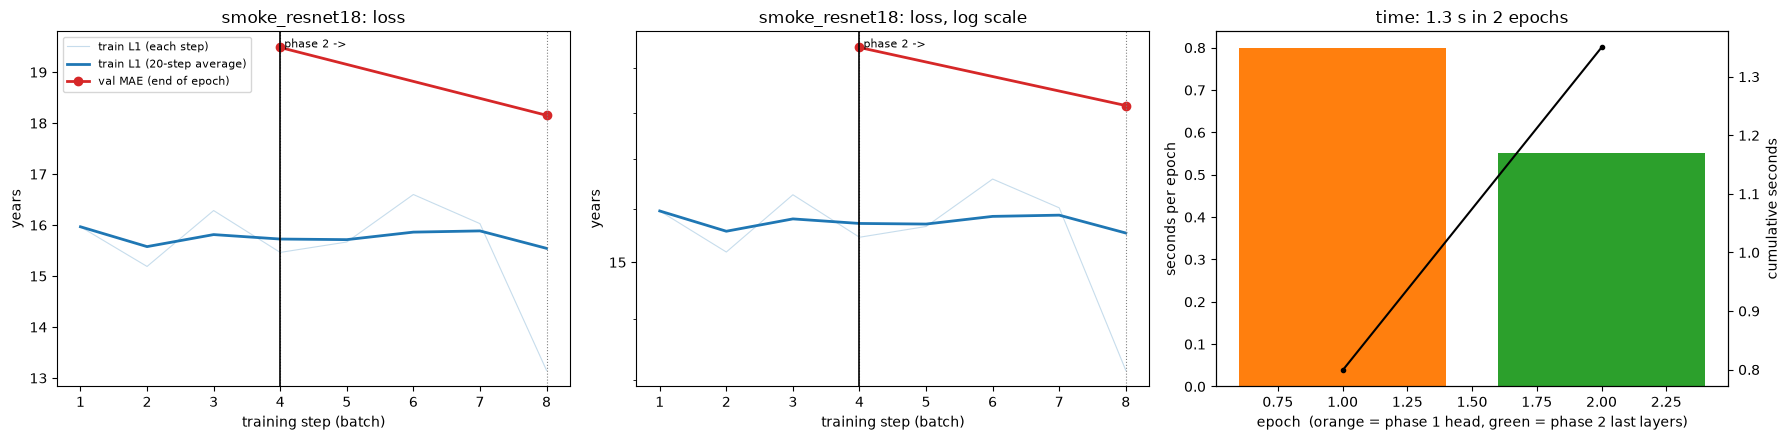

--- mobilenet_v3_large ---
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


epoch  1 [head]  train L1 15.731  |  val MAE 19.979  |  lr 1.0e-03  |   0.9 s
epoch  2 [last]  train L1 15.688  |  val MAE 19.722  |  lr 1.0e-03  |   0.2 s


[smoke_mobilenet_v3_large] ok | 1.7 s | 0.064 Wh (cpu 0.003, gpu 0.057, ram 0.005) | 0.030 g CO2eq
best val MAE 19.722 at epoch 2  ->  checkpoints/smoke_mobilenet_v3_large.pt  |  total 1.8 s


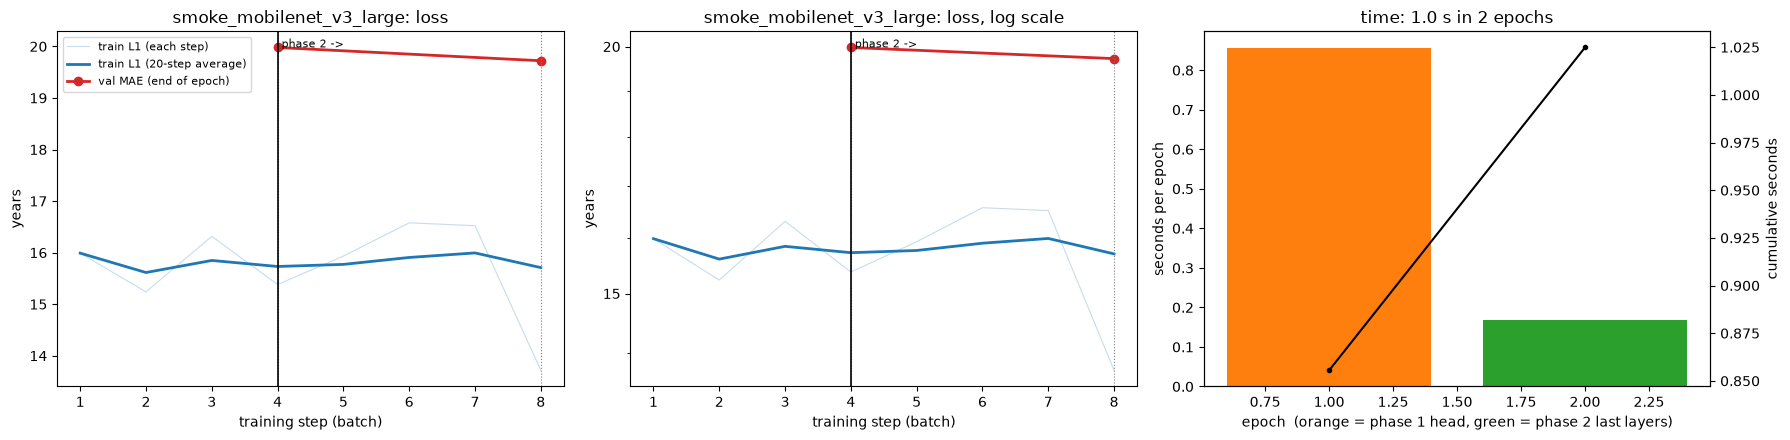

In [9]:
for name in ("resnet18", "mobilenet_v3_large"):
    print(f"--- {name} ---")
    _ = train_model(name, run_name=f"smoke_{name}", kind="test", n_train=512, n_val=256, max_epochs=2)